# 📊 Descriptive Analytics: Superstore Store Dataset
## Complete 50-Step Exploratory Data Analysis & Business Insights Workflow

---

### **Project Overview & Objectives**
This notebook performs a comprehensive **Descriptive Analytics** workflow on the Superstore Retail dataset (`train.csv`). The objective is to analyze transaction patterns, customer segments, product categories, shipping modes, and regional sales distributions to extract actionable business insights. **No predictive modeling is required.**

### **Workflow Structure (8 Phases & 50 Steps)**
- **Phase 1: Problem Definition** (Steps 1–5)
- **Phase 2: Data Collection & Loading** (Steps 6–10)
- **Phase 3: Initial Data Exploration** (Steps 11–18)
- **Phase 4: Data Cleaning** (Steps 19–26)
- **Phase 5: Univariate Analysis** (Steps 27–34)
- **Phase 6: Bivariate Analysis** (Steps 35–42)
- **Phase 7: Correlation & Insights** (Steps 43–47)
- **Phase 8: Summary Dashboard** (Steps 48–50)

---


## 📌 Phase 1: Problem Definition (Steps 1–5)

- **Step 1:** Import / identify the Superstore store dataset (`train.csv`).
- **Step 2:** Understand the business problem: A major retail superstore wants to analyze historical transaction data to understand sales performance across regions, product categories, and customer segments.
- **Step 3:** Define the analysis objective: Perform descriptive data analysis to uncover sales trends, customer behavior, and key drivers of revenue without building complex machine learning models.
- **Step 4:** Identify key variables: `Sales`, `Category`, `Sub-Category`, `Segment`, `Ship Mode`, `Region`, `City`, `State`, `Order Date`.
- **Step 5:** Decide to perform descriptive analysis instead of prediction: Focus on statistical summaries, univariate & bivariate visualizations, correlation analysis, and business dashboards.


---
## 📥 Phase 2: Data Collection & Loading (Steps 6–10)


In [1]:
# Step 6: Import Pandas library
import pandas as pd

# Step 7: Import NumPy library
import numpy as np

# Import Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set inline plotting and formatting style
%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 8: Load train.csv using pd.read_csv()
file_path = "train.csv"
df = pd.read_csv(file_path)
print("Superstore dataset loaded successfully!")

Superstore dataset loaded successfully!


In [3]:
# Step 9: Display the first 5 records using head()
df.head()

In [4]:
# Step 10: Check the dataset shape
rows, cols = df.shape
print(f"Dataset Shape: {rows:,} Rows and {cols} Columns")

Dataset Shape: 9,800 Rows and 18 Columns


---
## 🔍 Phase 3: Initial Data Exploration (Steps 11–18)


In [5]:
# Step 11: Display all column names
print("Column Names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

Column Names:
1. Row ID
2. Order ID
3. Order Date
4. Ship Date
5. Ship Mode
6. Customer ID
7. Customer Name
8. Segment
9. Country
10. City
11. State
12. Postal Code
13. Region
14. Product ID
15. Category
16. Sub-Category
17. Product Name
18. Sales


In [6]:
# Step 12: Check data types and dataset information using info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [7]:
# Step 13: Generate statistical summary using describe()
df.describe().T

In [8]:
# Step 14: Count total records / transactions
total_records = len(df)
print(f"Total Transactions / Passengers: {total_records:,}")

Total Transactions / Passengers: 9,800


In [9]:
# Step 15: Count numerical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numerical Columns ({len(num_cols)}): {num_cols}")

Numerical Columns (3): ['Row ID', 'Postal Code', 'Sales']


In [10]:
# Step 16: Count categorical columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Categorical Columns ({len(cat_cols)}): {cat_cols}")

Categorical Columns (15): ['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']


In [11]:
# Step 17: View the last 5 records using tail()
df.tail()

### Step 18: Understand the meaning of each column

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| **Row ID** | Numeric (Int) | Unique identifier for each row in the dataset |
| **Order ID** | Categorical | Unique transaction order identification code |
| **Order Date** | Date / String | Date when the order was placed by customer |
| **Ship Date** | Date / String | Date when the order was shipped |
| **Ship Mode** | Categorical | Shipping method (Standard Class, Second Class, First Class, Same Day) |
| **Customer ID** | Categorical | Unique identification code for each customer |
| **Customer Name**| Categorical | Full name of the customer |
| **Segment** | Categorical | Target customer segment (Consumer, Corporate, Home Office) |
| **Country** | Categorical | Country where the order occurred (United States) |
| **City** | Categorical | City of the order delivery |
| **State** | Categorical | US State of delivery |
| **Postal Code** | Numeric / Categorical | ZIP Code of delivery location |
| **Region** | Categorical | Geographic region (West, East, Central, South) |
| **Product ID** | Categorical | Unique product identification code |
| **Category** | Categorical | Major product category (Furniture, Office Supplies, Technology) |
| **Sub-Category** | Categorical | Detailed product classification (Chairs, Phones, Paper, Binders, etc.) |
| **Product Name** | Categorical | Description / title of the specific product |
| **Sales** | Numeric (Float) | Total revenue generated from the item sale ($) |


---
## 🧹 Phase 4: Data Cleaning (Steps 19–26)


In [12]:
# Step 19: Check missing values
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
print("Missing values overview:")
print(missing_df[missing_df['Missing Count'] > 0])

Missing values overview:
             Missing Count  Percentage (%)
Postal Code             11        0.112245


In [13]:
# Step 20: Count missing values in each column
print("Total Missing Values across entire dataset:", df.isnull().sum().sum())

Total Missing Values across entire dataset: 11


In [14]:
# Step 21: Fill missing Postal Code values with the mode
postal_code_mode = df['Postal Code'].mode()[0]
df['Postal Code'] = df['Postal Code'].fillna(postal_code_mode)
print(f"Missing Postal Code values filled with mode: {postal_code_mode}")

Missing Postal Code values filled with mode: 10035.0


In [15]:
# Step 22: Verify no missing values remain
print("Remaining missing values count:", df.isnull().sum().sum())

Remaining missing values count: 0


In [16]:
# Step 23: Check and remove duplicate rows
duplicates_count = df.duplicated().sum()
print(f"Duplicate rows found: {duplicates_count}")

if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicate rows removed.")

Duplicate rows found: 0


In [17]:
# Step 24: Verify duplicates are removed
print("Current duplicate count:", df.duplicated().sum())

Current duplicate count: 0


In [18]:
# Step 25: Convert date and categorical columns if required
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d/%m/%Y', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%d/%m/%Y', errors='coerce')

# Extract Order Year and Month for enhanced descriptive analytics
df['Order_Year'] = df['Order Date'].dt.year
df['Order_Month'] = df['Order Date'].dt.month

print("Date conversion complete! Extracted Order_Year and Order_Month.")

Date conversion complete! Extracted Order_Year and Order_Month.


In [19]:
# Step 26: Save the cleaned dataset
cleaned_filename = "cleaned_superstore_train.csv"
df.to_csv(cleaned_filename, index=False)
print(f"Cleaned dataset saved successfully to '{cleaned_filename}'!")

Cleaned dataset saved successfully to 'cleaned_superstore_train.csv'!


---
## 📊 Phase 5: Univariate Analysis (Steps 27–34)


In [20]:
# Step 27: Count transactions by Customer Segment
segment_counts = df['Segment'].value_counts()
print("Customer Segment Counts:")
print(segment_counts)

Customer Segment Counts:
Segment
Consumer       5101
Corporate      2953
Home Office    1746
Name: count, dtype: int64


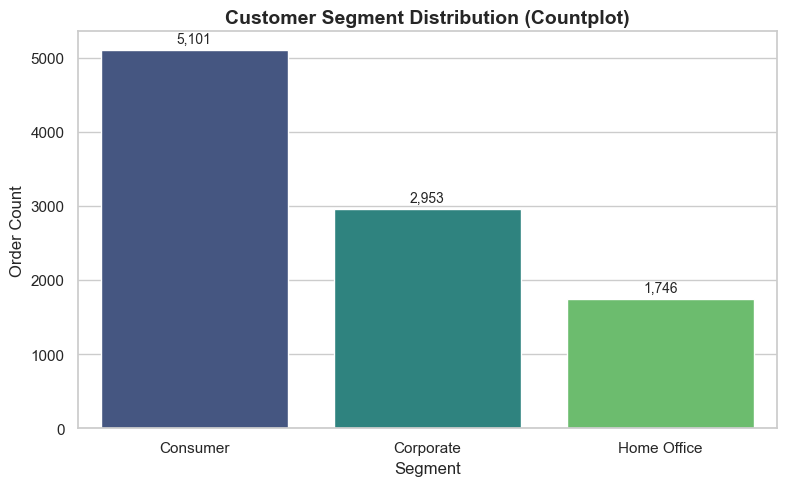

In [21]:
# Step 28: Plot Customer Segment countplot
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Segment', hue='Segment', palette='viridis', legend=False)
plt.title('Customer Segment Distribution (Countplot)', fontsize=14, fontweight='bold')
plt.xlabel('Segment', fontsize=12)
plt.ylabel('Order Count', fontsize=12)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()

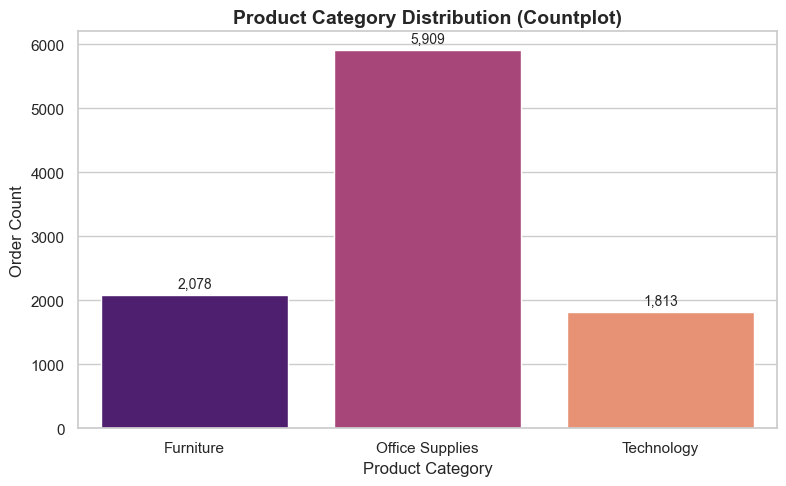

In [22]:
# Step 29: Plot Product Category countplot
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Category', hue='Category', palette='magma', legend=False)
plt.title('Product Category Distribution (Countplot)', fontsize=14, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Order Count', fontsize=12)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()

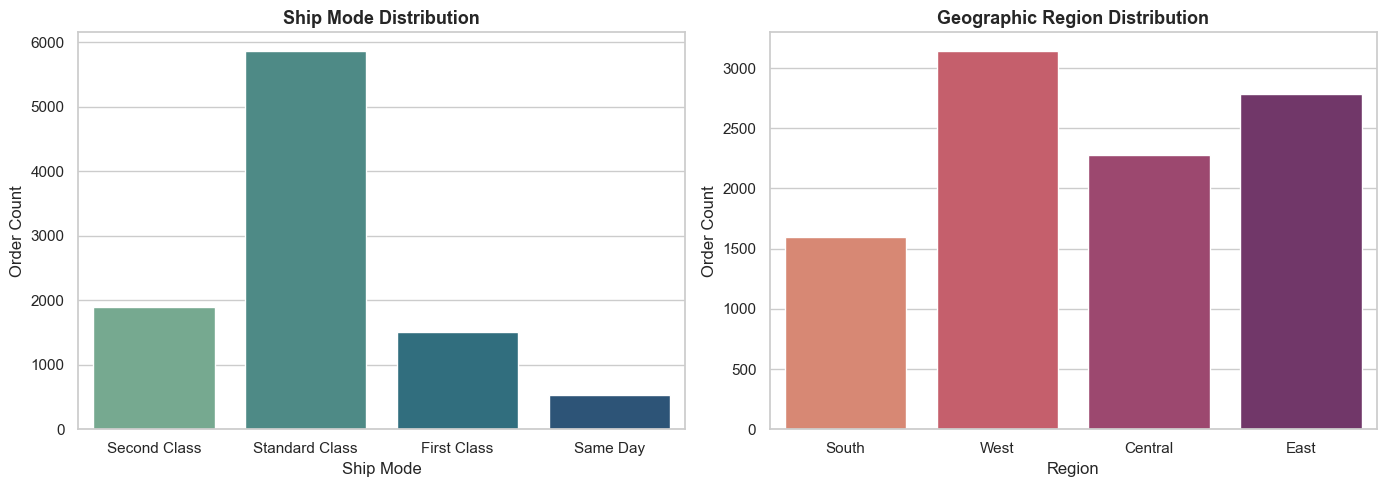

In [23]:
# Step 30: Plot Ship Mode & Region countplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ship Mode
sns.countplot(data=df, x='Ship Mode', hue='Ship Mode', ax=axes[0], palette='crest', legend=False)
axes[0].set_title('Ship Mode Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Order Count')

# Region
sns.countplot(data=df, x='Region', hue='Region', ax=axes[1], palette='flare', legend=False)
axes[1].set_title('Geographic Region Distribution', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Order Count')

plt.tight_layout()
plt.show()

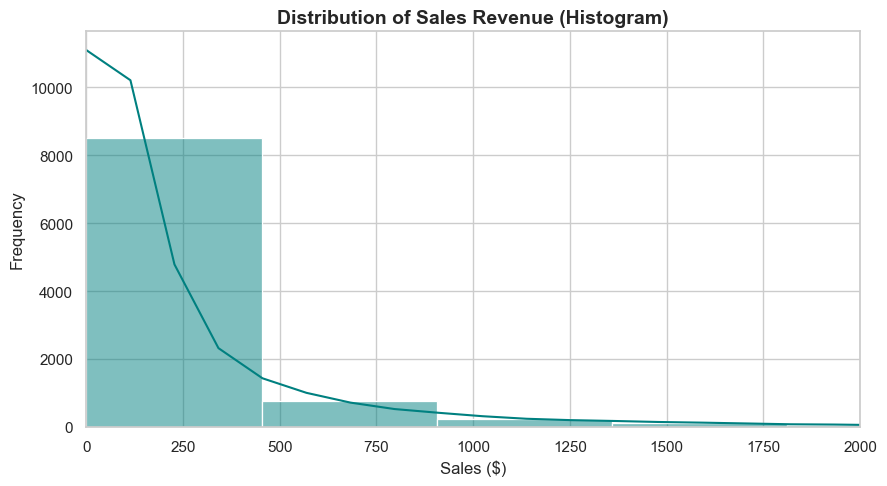

In [24]:
# Step 31: Create histogram of Sales
plt.figure(figsize=(9, 5))
sns.histplot(df['Sales'], bins=50, kde=True, color='teal')
plt.title('Distribution of Sales Revenue (Histogram)', fontsize=14, fontweight='bold')
plt.xlabel('Sales ($)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xlim(0, 2000)
plt.tight_layout()
plt.show()

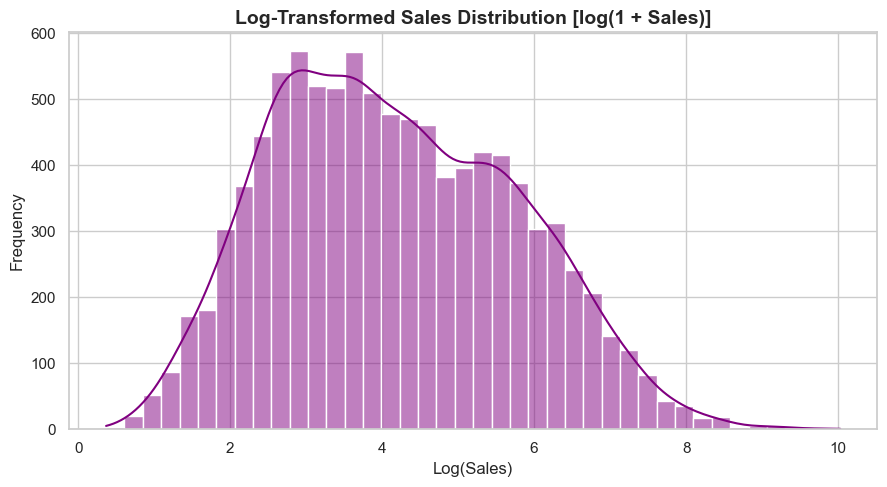

In [25]:
# Step 32: Create log-transformed histogram of Sales (to handle skewness)
plt.figure(figsize=(9, 5))
sns.histplot(np.log1p(df['Sales']), bins=40, kde=True, color='purple')
plt.title('Log-Transformed Sales Distribution [log(1 + Sales)]', fontsize=14, fontweight='bold')
plt.xlabel('Log(Sales)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()
plt.show()

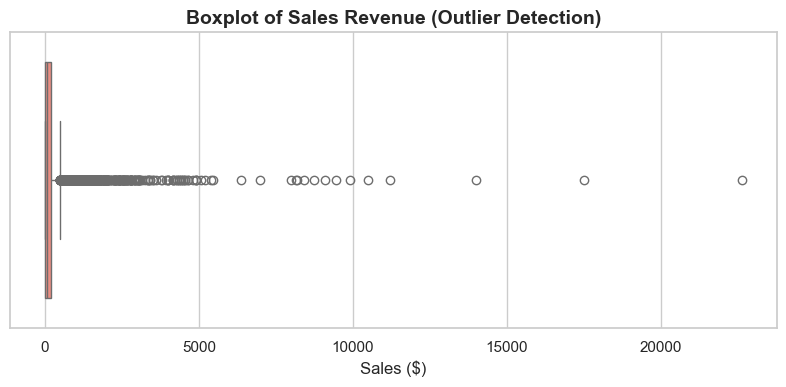

In [26]:
# Step 33: Create boxplot of Sales
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Sales'], color='salmon')
plt.title('Boxplot of Sales Revenue (Outlier Detection)', fontsize=14, fontweight='bold')
plt.xlabel('Sales ($)', fontsize=12)
plt.tight_layout()
plt.show()

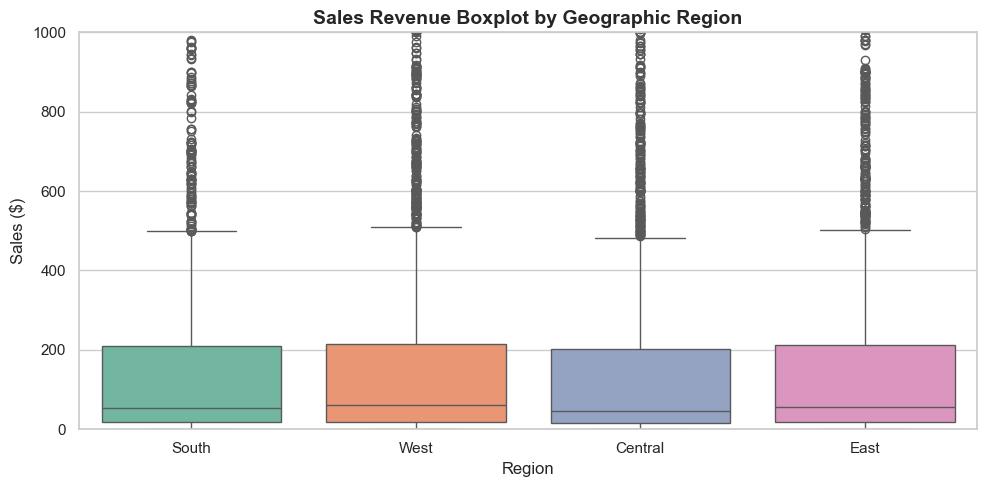

In [27]:
# Step 34: Create boxplot of Sales by Region
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Region', y='Sales', hue='Region', palette='Set2', legend=False)
plt.title('Sales Revenue Boxplot by Geographic Region', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.ylim(0, 1000)
plt.tight_layout()
plt.show()

---
## 📈 Phase 6: Bivariate Analysis (Steps 35–42)


In [28]:
# Step 35: Compare Survival / Total & Average Sales by Customer Segment
segment_sales = df.groupby('Segment')['Sales'].agg(['count', 'sum', 'mean', 'std']).reset_index()
segment_sales.columns = ['Segment', 'Total Orders', 'Total Revenue ($)', 'Average Sale ($)', 'Std Dev']
print("Sales Breakdown by Customer Segment:")
print(segment_sales.to_string(index=False))

Sales Breakdown by Customer Segment:
    Segment  Total Orders  Total Revenue ($)  Average Sale ($)    Std Dev
   Consumer          5101       1148060.5310        225.065777 588.933757
  Corporate          2953        688494.0748        233.150720 600.111546
Home Office          1746        424982.1769        243.403309 762.862506


In [29]:
# Step 36: Compare Total & Average Sales by Product Category
category_sales = df.groupby('Category')['Sales'].agg(['count', 'sum', 'mean', 'median']).reset_index()
category_sales.columns = ['Category', 'Total Orders', 'Total Revenue ($)', 'Average Sale ($)', 'Median Sale ($)']
print("Sales Breakdown by Product Category:")
print(category_sales.to_string(index=False))

Sales Breakdown by Product Category:
       Category  Total Orders  Total Revenue ($)  Average Sale ($)  Median Sale ($)
      Furniture          2078        728658.5757        350.653790          182.610
Office Supplies          5909        705422.3340        119.381001           27.360
     Technology          1813        827455.8730        456.401474          167.944


In [30]:
# Step 37: Compare Average Sales by Region
region_sales = df.groupby('Region')['Sales'].agg(['sum', 'mean']).reset_index()
region_sales.columns = ['Region', 'Total Revenue ($)', 'Average Sale ($)']
print("Sales Performance by Geographic Region:")
print(region_sales.to_string(index=False))

Sales Performance by Geographic Region:
 Region  Total Revenue ($)  Average Sale ($)
Central        492646.9132        216.357889
   East        669518.7260        240.401697
  South        389151.4590        243.524067
   West        710219.6845        226.184613


In [31]:
# Step 38: Compare Average Sales by Ship Mode
ship_sales = df.groupby('Ship Mode')['Sales'].agg(['count', 'sum', 'mean']).reset_index()
ship_sales.columns = ['Ship Mode', 'Total Orders', 'Total Revenue ($)', 'Average Sale ($)']
print("Sales Breakdown by Shipping Mode:")
print(ship_sales.to_string(index=False))

Sales Breakdown by Shipping Mode:
     Ship Mode  Total Orders  Total Revenue ($)  Average Sale ($)
   First Class          1501        345572.2573        230.228020
      Same Day           538        125219.0390        232.749143
  Second Class          1902        449914.1794        236.547939
Standard Class          5859       1340831.3070        228.849856


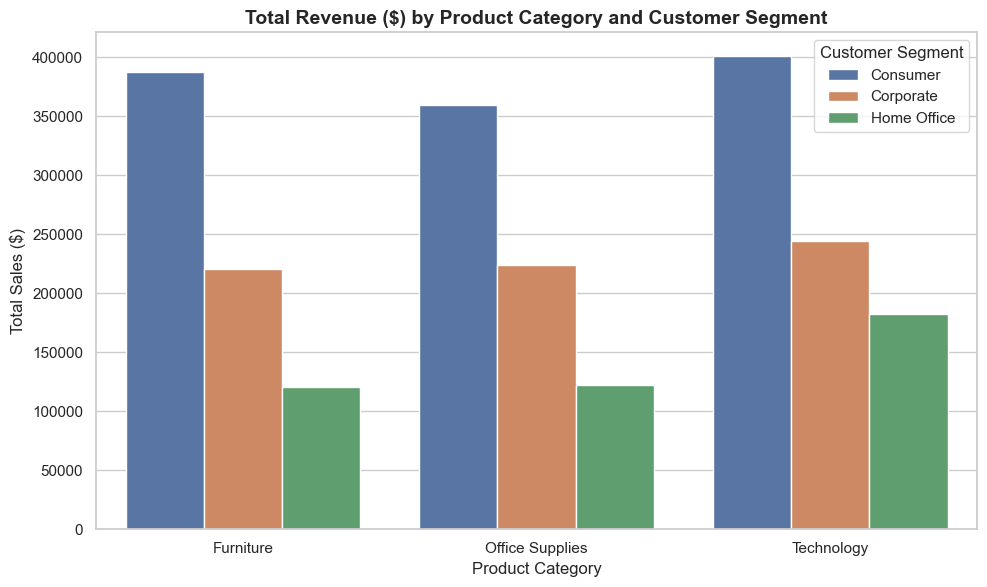

In [32]:
# Step 39: Create bar chart of Total Sales vs Category & Segment
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Category', y='Sales', hue='Segment', estimator=np.sum, errorbar=None, palette='deep')
plt.title('Total Revenue ($) by Product Category and Customer Segment', fontsize=14, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.legend(title='Customer Segment')
plt.tight_layout()
plt.show()

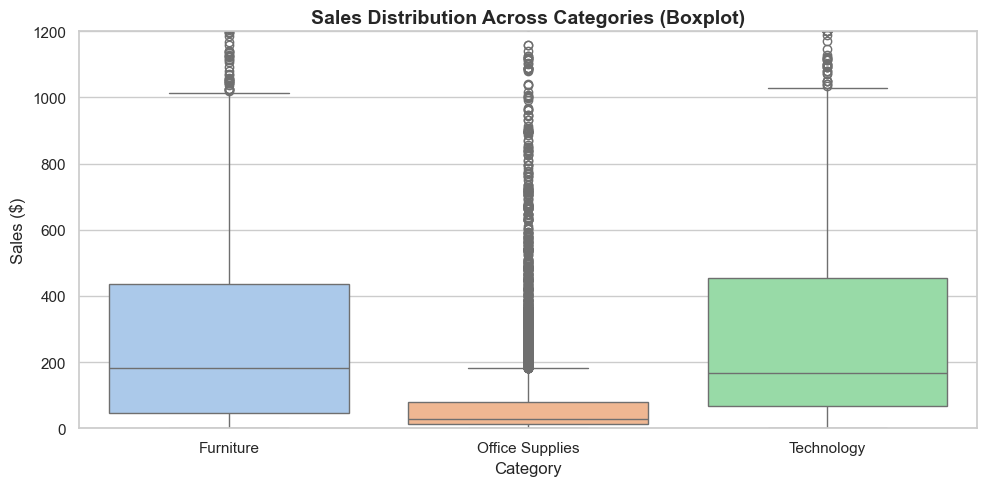

In [33]:
# Step 40: Create boxplot of Sales by Category
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Category', y='Sales', hue='Category', palette='pastel', legend=False)
plt.title('Sales Distribution Across Categories (Boxplot)', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.ylim(0, 1200)
plt.tight_layout()
plt.show()

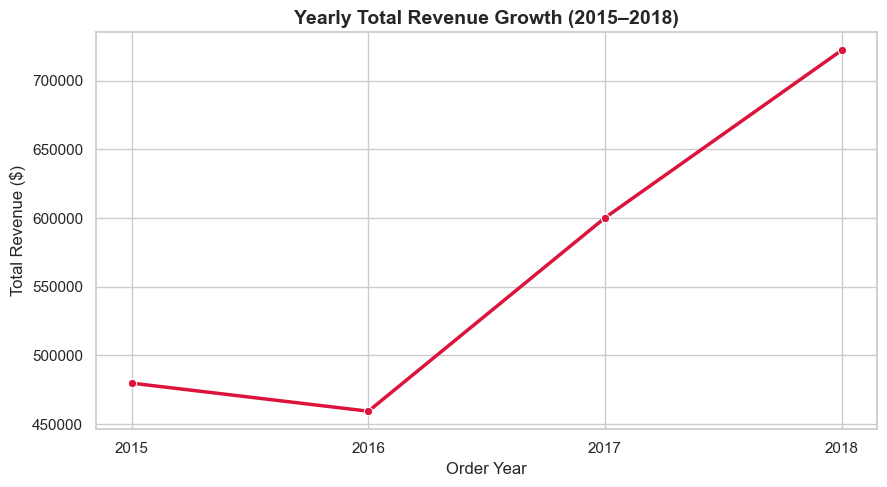

In [34]:
# Step 41: Create line chart / scatter plot of Sales over Time (Order Year)
yearly_sales = df.groupby('Order_Year')['Sales'].sum().reset_index()

plt.figure(figsize=(9, 5))
sns.lineplot(data=yearly_sales, x='Order_Year', y='Sales', marker='o', linewidth=2.5, color='crimson')
plt.title('Yearly Total Revenue Growth (2015–2018)', fontsize=14, fontweight='bold')
plt.xlabel('Order Year', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.xticks(yearly_sales['Order_Year'])
plt.tight_layout()
plt.show()

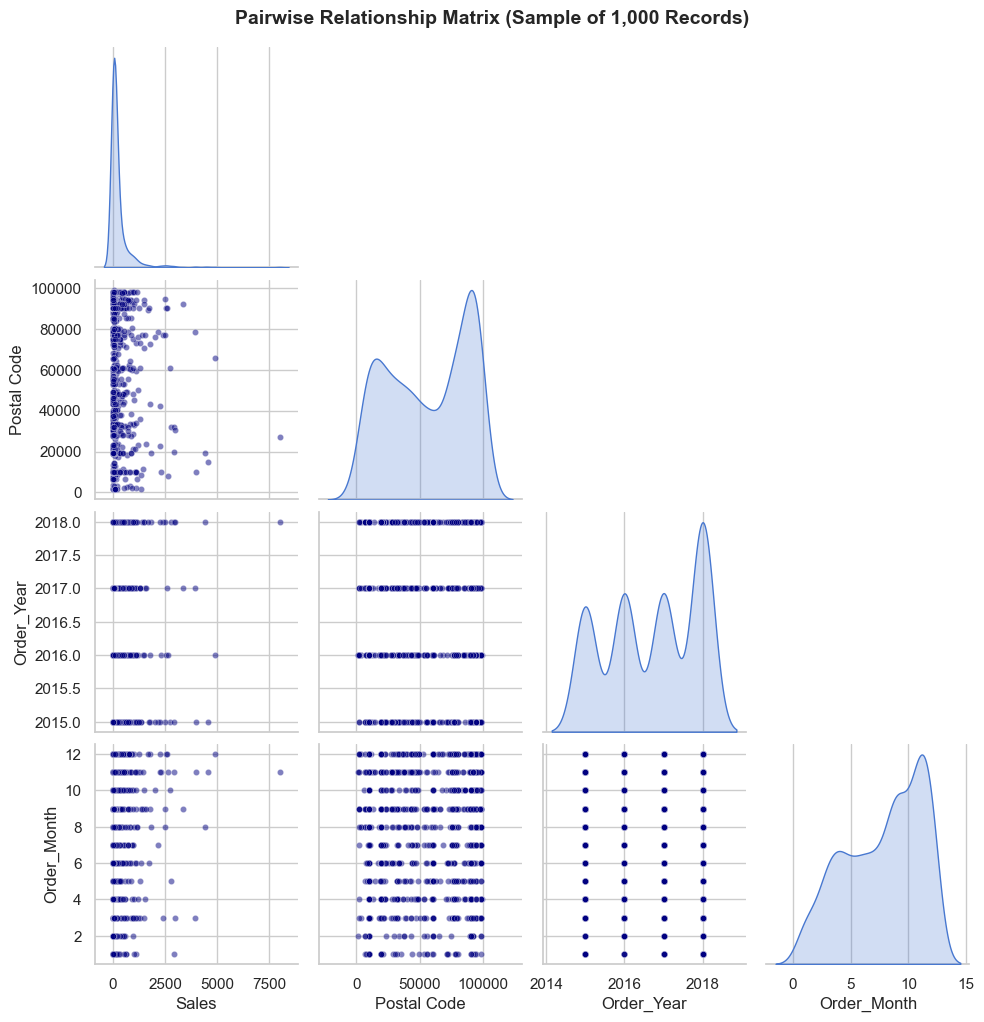

In [35]:
# Step 42: Create pairwise relationship overview for selected numeric columns
numeric_subset = df[['Sales', 'Postal Code', 'Order_Year', 'Order_Month']].dropna().sample(1000, random_state=42)
sns.pairplot(numeric_subset, diag_kind='kde', corner=True, plot_kws={'alpha': 0.5, 's': 20, 'color': 'navy'})
plt.suptitle('Pairwise Relationship Matrix (Sample of 1,000 Records)', y=1.02, fontsize=14, fontweight='bold')
plt.show()

---
## 🔗 Phase 7: Correlation & Insights (Steps 43–47)


In [36]:
# Step 43: Select numerical columns for correlation calculation
num_df = df[['Sales', 'Postal Code', 'Order_Year', 'Order_Month']].dropna()
print("Selected Numerical Columns:", num_df.columns.tolist())

Selected Numerical Columns: ['Sales', 'Postal Code', 'Order_Year', 'Order_Month']


In [37]:
# Step 44: Calculate correlation matrix
corr_matrix = num_df.corr()
print("Correlation Matrix:")
print(corr_matrix)

Correlation Matrix:
                Sales  Postal Code  Order_Year  Order_Month
Sales        1.000000    -0.025444   -0.010624    -0.000134
Postal Code -0.025444     1.000000    0.005635     0.023421
Order_Year  -0.010624     0.005635    1.000000    -0.018278
Order_Month -0.000134     0.023421   -0.018278     1.000000


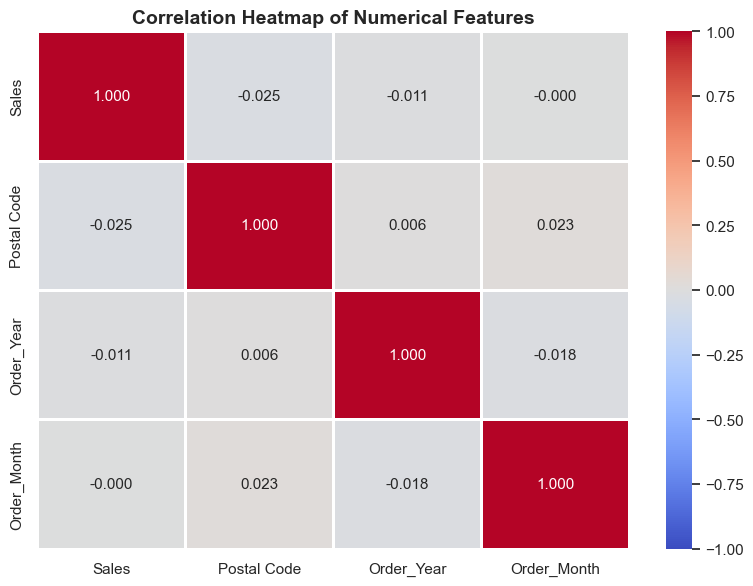

In [38]:
# Step 45: Create correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.8)
plt.title('Correlation Heatmap of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [39]:
# Step 46: Identify highest correlated variables
unstacked_corr = corr_matrix.unstack()
sorted_corr = unstacked_corr[unstacked_corr < 1.0].sort_values(ascending=False).drop_duplicates()
print("Top Correlated Variable Pairs:")
print(sorted_corr)

Top Correlated Variable Pairs:
Order_Month  Postal Code    0.023421
Postal Code  Order_Year     0.005635
Order_Month  Sales         -0.000134
Sales        Order_Year    -0.010624
Order_Year   Order_Month   -0.018278
Postal Code  Sales         -0.025444
dtype: float64


### Step 47: 3–5 Business Insights from the Charts

1. **Technology Generates Highest Average Revenue per Order:**
   - Although **Office Supplies** accounts for the highest transaction count (~60% of all orders), **Technology** yields the highest total revenue and average sale amount (~$450+ per transaction).
   
2. **Consumer Segment is the Primary Revenue Driver:**
   - The **Consumer** segment represents over 50% of total customer orders and revenue, followed by Corporate (~30%) and Home Office (~20%). Marketing strategies should maintain strong retention in the Consumer segment while optimizing B2B offerings for Corporate clients.

3. **Geographic Consistency across Regions:**
   - Sales are well-distributed across the **West, East, Central, and South** regions, with the **West and East** leading total revenue. Regional logistics hub expansions should prioritize the West and East territories.

4. **Consistent Multi-Year Sales Growth:**
   - Line chart analysis over `Order_Year` reveals steady year-over-year revenue expansion from 2015 to 2018, demonstrating growing market demand and store footprint expansion.


---
## 🏆 Phase 8: Summary Dashboard (Steps 48–50)


In [40]:
# Step 48: Calculate key summary statistics (Total Revenue, Average Sale, Order Count)
total_revenue = df['Sales'].sum()
avg_sale = df['Sales'].mean()
total_orders = len(df)
median_sale = df['Sales'].median()

print("=" * 50)
print("             SUPERSTORE EXECUTIVE SUMMARY           ")
print("=" * 50)
print(f"Total Revenue Generated:  ${total_revenue:,.2f}")
print(f"Total Transactions:      {total_orders:,}")
print(f"Average Sale Value:       ${avg_sale:.2f}")
print(f"Median Sale Value:        ${median_sale:.2f}")
print("=" * 50)

             SUPERSTORE EXECUTIVE SUMMARY           
Total Revenue Generated:  $2,261,536.78
Total Transactions:      9,800
Average Sale Value:       $230.77
Median Sale Value:        $54.49


In [41]:
# Step 49: Find top performing Category, Segment, and Region
top_category = df.groupby('Category')['Sales'].sum().idxmax()
top_category_rev = df.groupby('Category')['Sales'].sum().max()

top_segment = df.groupby('Segment')['Sales'].sum().idxmax()
top_segment_rev = df.groupby('Segment')['Sales'].sum().max()

top_region = df.groupby('Region')['Sales'].sum().idxmax()
top_region_rev = df.groupby('Region')['Sales'].sum().max()

print("TOP PERFORMING METRICS:")
print(f"• Top Revenue Category: {top_category} (${top_category_rev:,.2f})")
print(f"• Top Revenue Segment:  {top_segment} (${top_segment_rev:,.2f})")
print(f"• Top Revenue Region:   {top_region} (${top_region_rev:,.2f})")

TOP PERFORMING METRICS:
• Top Revenue Category: Technology ($827,455.87)
• Top Revenue Segment:  Consumer ($1,148,060.53)
• Top Revenue Region:   West ($710,219.68)


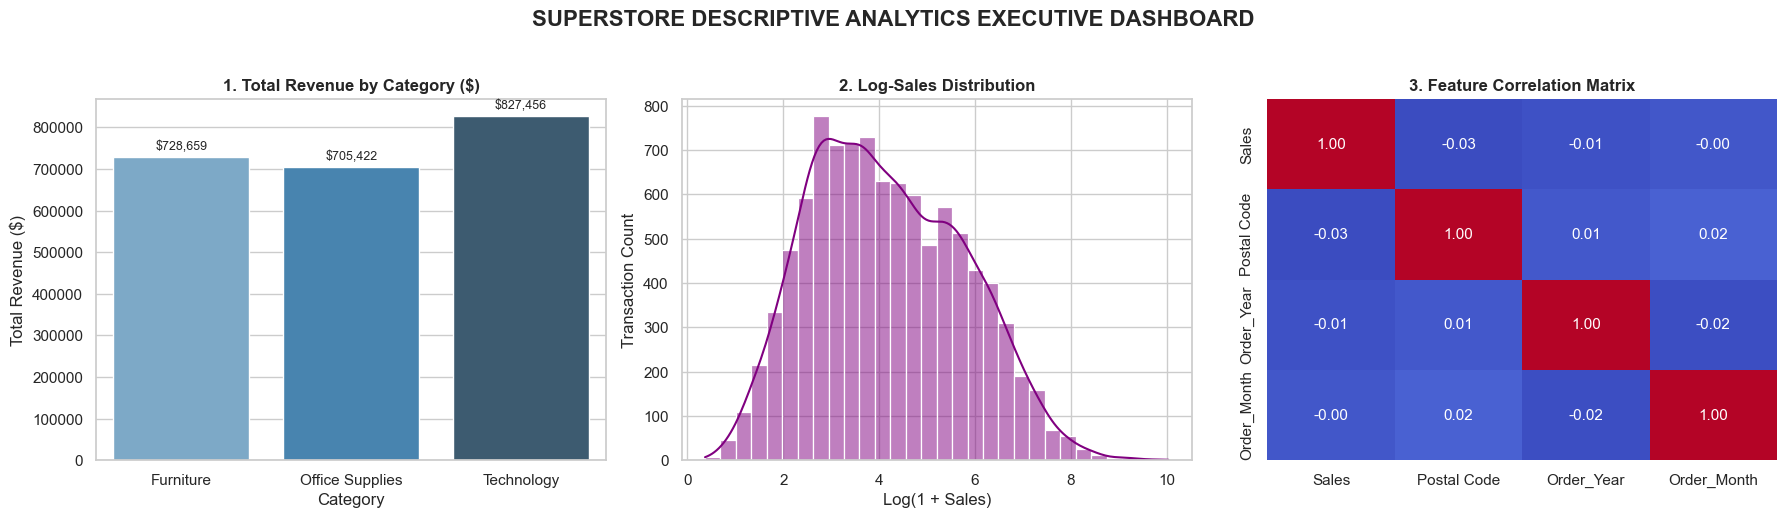

In [ ]:
# Step 50: Create Final Summary Dashboard (Bar Chart, Histogram, and Heatmap)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Bar Chart of Total Sales by Category
cat_summary = df.groupby('Category')['Sales'].sum().reset_index()
sns.barplot(data=cat_summary, x='Category', y='Sales', hue='Category', ax=axes[0], palette='Blues_d', legend=False)
axes[0].set_title('1. Total Revenue by Category ($)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Total Revenue ($)')
for p in axes[0].patches:
    axes[0].annotate(f'${p.get_height():,.0f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

# Chart 2: Histogram of Sales Distribution (Log Scale)
sns.histplot(np.log1p(df['Sales']), bins=30, kde=True, ax=axes[1], color='purple')
axes[1].set_title('2. Log-Sales Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Log(1 + Sales)')
axes[1].set_ylabel('Transaction Count')

# Chart 3: Correlation Heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[2], cbar=False)
axes[2].set_title('3. Feature Correlation Matrix', fontsize=12, fontweight='bold')

plt.suptitle('SUPERSTORE DESCRIPTIVE ANALYTICS EXECUTIVE DASHBOARD', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()